In [1]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

import os
import re
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)

print("PhishGuard initialized.")

PhishGuard initialized.


In [2]:
DATA_PATH = "/content/dataset_phishing.csv"

if not os.path.exists(DATA_PATH):
    from google.colab import files

    uploaded = files.upload()

    csv_files = [
        filename for filename in uploaded
        if filename.lower().endswith(".csv")
    ]

    if not csv_files:
        raise FileNotFoundError("Upload your phishing dataset CSV.")

    DATA_PATH = csv_files[0]

df = pd.read_csv(DATA_PATH, low_memory=False)

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

df = df.loc[
    :, ~df.columns.str.match(r"^(unnamed:|index$)", case=False)
]

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset shape: (11430, 89)
Columns: ['url', 'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 'nb_hyperlinks', 'ratio_inthyperlinks', 'ratio_exthyperlinks', 'rati

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate


**Inspect missing values and labels**

In [3]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(
    df.isna().sum()
    .sort_values(ascending=False)
    .head(30)
    .to_frame("missing_count")
)

if "url" not in df.columns or "status" not in df.columns:
    raise ValueError(
        "The CSV must contain columns named 'url' and 'status'."
    )

print("\nOriginal label distribution:")
display(df["status"].value_counts(dropna=False).to_frame("count"))

Data types:


,dtype
url,object
length_url,int64
length_hostname,int64
ip,int64
nb_dots,int64
...,...
web_traffic,int64
dns_record,int64
google_index,int64
page_rank,int64



Missing values:


,missing_count
url,0
length_url,0
length_hostname,0
ip,0
nb_dots,0
nb_hyphens,0
nb_at,0
nb_qm,0
nb_and,0
nb_or,0



Original label distribution:


,count
status,
legitimate,5715
phishing,5715


**Clean URLs and labels**

In [4]:
def clean_url(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    # Handle a URL accidentally stored as a Markdown link.
    match = re.fullmatch(
        r"\[([^\]]+)\]\((https?://[^)]+)\)",
        value
    )

    if match:
        value = match.group(2)

    value = re.sub(r"\s+", "", value)

    if value.lower() in {"", "nan", "none", "null"}:
        return np.nan

    return value


def clean_status(value):
    if pd.isna(value):
        return np.nan

    label = str(value).strip().lower()

    mapping = {
        "legitimate": 0,
        "legit": 0,
        "benign": 0,
        "safe": 0,
        "good": 0,
        "0": 0,
        "0.0": 0,

        "phishing": 1,
        "phish": 1,
        "malicious": 1,
        "bad": 1,
        "1": 1,
        "1.0": 1
    }

    return mapping.get(label, np.nan)


rows_before = len(df)

df["url"] = df["url"].apply(clean_url)
df["status"] = df["status"].apply(clean_status)

# Drop missing URLs and unknown labels
df = df.dropna(subset=["url", "status"]).copy()
df = df[df["url"].str.len() > 0].copy()

df["status"] = df["status"].astype(int)

# Remove exact duplicate rows
df = df.drop_duplicates()

# Remove URLs associated with conflicting labels
label_counts = df.groupby("url")["status"].nunique()

conflicting_urls = label_counts[
    label_counts > 1
].index

print("Conflicting URLs:", len(conflicting_urls))

df = df[
    ~df["url"].isin(conflicting_urls)
].copy()

# Prevent identical URLs from appearing in multiple splits
df = df.drop_duplicates(
    subset=["url"],
    keep="first"
).reset_index(drop=True)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))
print("Rows removed:", rows_before - len(df))

print("\nCleaned label distribution:")
display(
    df["status"]
    .value_counts()
    .rename(index={
        0: "legitimate",
        1: "phishing"
    })
    .to_frame("count")
)

if df["status"].nunique() != 2:
    raise ValueError(
        "Both legitimate and phishing examples are required."
    )

Conflicting URLs: 0
Rows before cleaning: 11430
Rows after cleaning: 11429
Rows removed: 1

Cleaned label distribution:


,count
status,
legitimate,5715
phishing,5714


**Clean numerical features**

In [5]:
numeric_features = [
    col for col in df.columns
    if col not in {"url", "status"}
]

# Convert malformed numerical values to NaN
for col in numeric_features:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Replace infinity with missing values
df[numeric_features] = df[numeric_features].replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove features with no valid data
all_missing = [
    col for col in numeric_features
    if df[col].isna().all()
]

# Remove constant features
constant = [
    col for col in numeric_features
    if col not in all_missing
    and df[col].nunique(dropna=True) <= 1
]

drop_cols = sorted(set(all_missing + constant))

print("All-missing columns:", all_missing)
print("Constant columns:", constant)

df = df.drop(columns=drop_cols)

numeric_features = [
    col for col in df.columns
    if col not in {"url", "status"}
]

print("Remaining numerical features:", len(numeric_features))
print("Cleaned shape:", df.shape)

display(
    (df[numeric_features].isna().mean() * 100)
    .sort_values(ascending=False)
    .head(20)
    .to_frame("missing_percentage")
)

All-missing columns: []
Constant columns: ['nb_or', 'ratio_nullhyperlinks', 'ratio_intredirection', 'ratio_interrors', 'submit_email', 'sfh']
Remaining numerical features: 81
Cleaned shape: (11429, 83)


,missing_percentage
length_url,0.0
length_hostname,0.0
ip,0.0
nb_dots,0.0
nb_hyphens,0.0
nb_at,0.0
nb_qm,0.0
nb_and,0.0
nb_eq,0.0
nb_underscore,0.0


**Visualize the cleaned dataset**

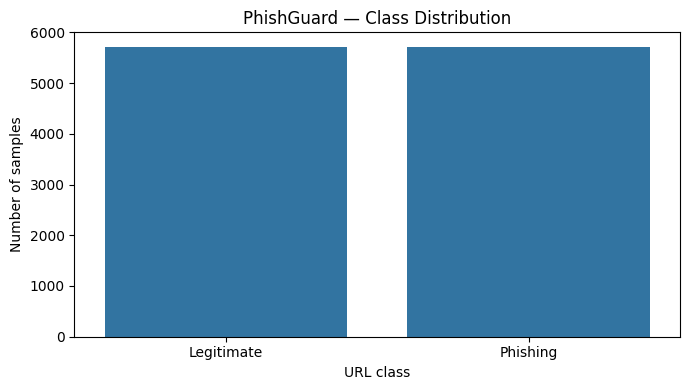

In [19]:
OUTPUT_DIR = "/content/phishguard_artifacts"
os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.figure(figsize=(7, 4))
sns.countplot(
    data=df,
    x="status"
)

plt.xticks(
    [0, 1],
    ["Legitimate", "Phishing"]
)

plt.title("PhishGuard — Class Distribution")
plt.xlabel("URL class")
plt.ylabel("Number of samples")
plt.tight_layout()

# Save image immediately
plt.savefig(os.path.join(OUTPUT_DIR, "class_distribution.png"), dpi=300)
plt.show()

In [7]:
trainval_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["status"]
)

train_df, val_df = train_test_split(
    trainval_df,
    test_size=0.20,
    random_state=SEED,
    stratify=trainval_df["status"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

X_train = train_df[["url"] + numeric_features]
y_train = train_df["status"]

X_val = val_df[["url"] + numeric_features]
y_val = val_df["status"]

X_test = test_df[["url"] + numeric_features]
y_test = test_df["status"]

Training samples: 7314
Validation samples: 1829
Test samples: 2286


**Preprocessing pipeline**

In [8]:
url_transformer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    max_features=200_000,
    min_df=2,
    sublinear_tf=True,
    dtype=np.float32
)

transformers = [
    ("url_text", url_transformer, "url")
]

if numeric_features:
    numeric_transformer = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler(with_mean=False)
        )
    ])

    transformers.append(
        ("numeric", numeric_transformer, numeric_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    sparse_threshold=1.0
)

print("URL TF-IDF configured.")
print("Numeric feature processing configured.")

URL TF-IDF configured.
Numeric feature processing configured.


**Train and compare models**

In [9]:
candidates = {
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=SEED
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED
    )
}

fitted_models = {}
results = []

for name, classifier in candidates.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    start = time.perf_counter()

    pipeline.fit(
        X_train,
        y_train
    )

    training_time = time.perf_counter() - start

    start = time.perf_counter()

    val_pred = pipeline.predict(X_val)

    inference_time = time.perf_counter() - start

    if hasattr(pipeline, "decision_function"):
        val_scores = pipeline.decision_function(X_val)
    else:
        val_scores = pipeline.predict_proba(X_val)[:, 1]

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_val, val_pred),
        "balanced_accuracy": balanced_accuracy_score(y_val, val_pred),
        "phishing_precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "phishing_recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "phishing_f1": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, val_scores),
        "training_seconds": training_time,
        "prediction_seconds": inference_time
    })

    fitted_models[name] = pipeline

    print(f"Finished training {name}")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["phishing_f1", "phishing_recall"],
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Finished training Linear SVM
Finished training Logistic Regression


,model,accuracy,balanced_accuracy,phishing_precision,phishing_recall,phishing_f1,roc_auc,training_seconds,prediction_seconds
0,Linear SVM,0.9716,0.9716,0.9705,0.9726,0.9716,0.9941,3.1896,0.1956
1,Logistic Regression,0.9584,0.9584,0.9554,0.9617,0.9586,0.9908,4.1622,0.2382


**Visualize model comparison**

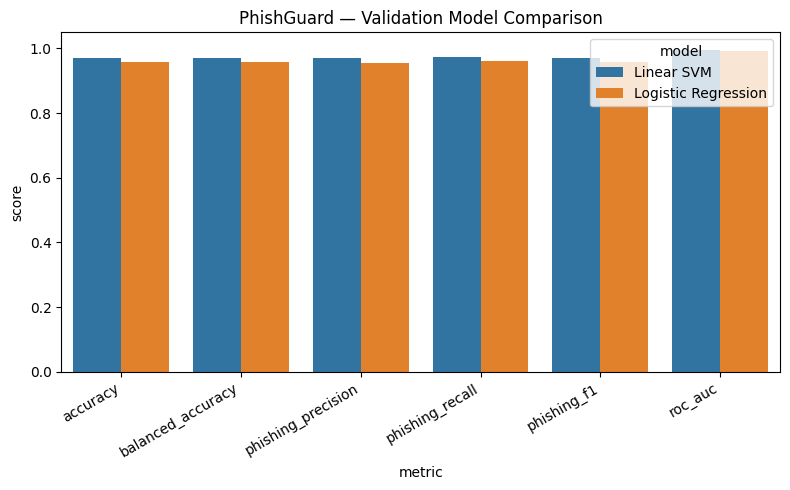

In [20]:
plt.figure(figsize=(8, 5))

plot_data = results_df.melt(
    id_vars="model",
    value_vars=[
        "accuracy",
        "balanced_accuracy",
        "phishing_precision",
        "phishing_recall",
        "phishing_f1",
        "roc_auc"
    ],
    var_name="metric",
    value_name="score"
)

sns.barplot(
    data=plot_data,
    x="metric",
    y="score",
    hue="model"
)

plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.title("PhishGuard — Validation Model Comparison")
plt.tight_layout()

# Save image immediately
plt.savefig(os.path.join(OUTPUT_DIR, "validation_model_comparison.png"), dpi=300)
plt.show()

**Select best model**

In [11]:
best_name = results_df.iloc[0]["model"]
best_model = fitted_models[best_name]

print("Selected model:", best_name)
print("Selection is based on validation phishing F1,")
print("with phishing recall as a tie-breaker.")

Selected model: Linear SVM
Selection is based on validation phishing F1,
with phishing recall as a tie-breaker.


              precision    recall  f1-score   support

  Legitimate       0.97      0.97      0.97       915
    Phishing       0.97      0.97      0.97       914

    accuracy                           0.97      1829
   macro avg       0.97      0.97      0.97      1829
weighted avg       0.97      0.97      0.97      1829



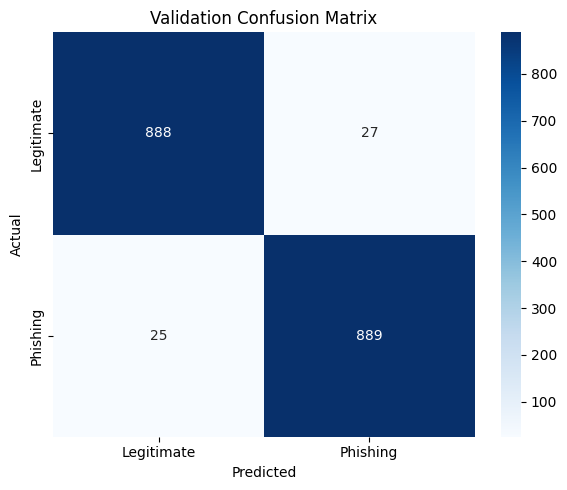

In [21]:
val_pred = best_model.predict(X_val)

print(
    classification_report(
        y_val,
        val_pred,
        labels=[0, 1],
        target_names=["Legitimate", "Phishing"],
        zero_division=0
    )
)

cm_val = confusion_matrix(
    y_val,
    val_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_val,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Validation Confusion Matrix")
plt.tight_layout()

# Save image immediately
plt.savefig(os.path.join(OUTPUT_DIR, "validation_confusion_matrix.png"), dpi=300)
plt.show()

**Final test evaluation**

,model,accuracy,balanced_accuracy,phishing_precision,phishing_recall,phishing_f1,roc_auc
0,Linear SVM,0.9633,0.9633,0.969,0.9571,0.963,0.9904


              precision    recall  f1-score   support

  Legitimate       0.96      0.97      0.96      1143
    Phishing       0.97      0.96      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286



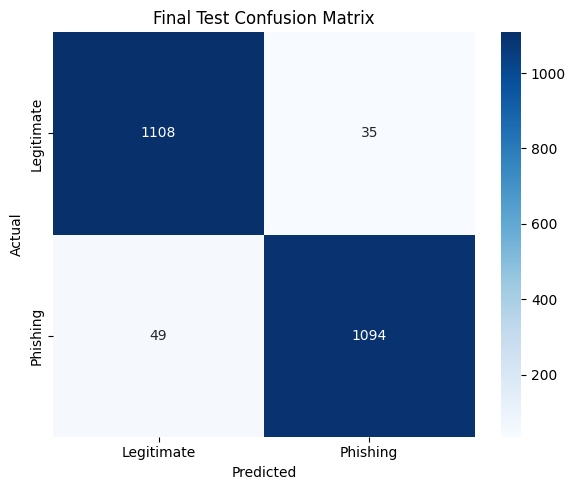

In [22]:
test_pred = best_model.predict(X_test)

if hasattr(best_model, "decision_function"):
    test_scores = best_model.decision_function(X_test)
else:
    test_scores = best_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "model": best_name,
    "accuracy": accuracy_score(y_test, test_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, test_pred),
    "phishing_precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "phishing_recall": recall_score(
        y_test, test_pred, zero_division=0
    ),
    "phishing_f1": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, test_scores)
}

display(
    pd.DataFrame([test_metrics]).round(4)
)

print(
    classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["Legitimate", "Phishing"],
        zero_division=0
    )
)

cm_test = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Test Confusion Matrix")
plt.tight_layout()

# Save image immediately
plt.savefig(os.path.join(OUTPUT_DIR, "final_test_confusion_matrix.png"), dpi=300)
plt.show()

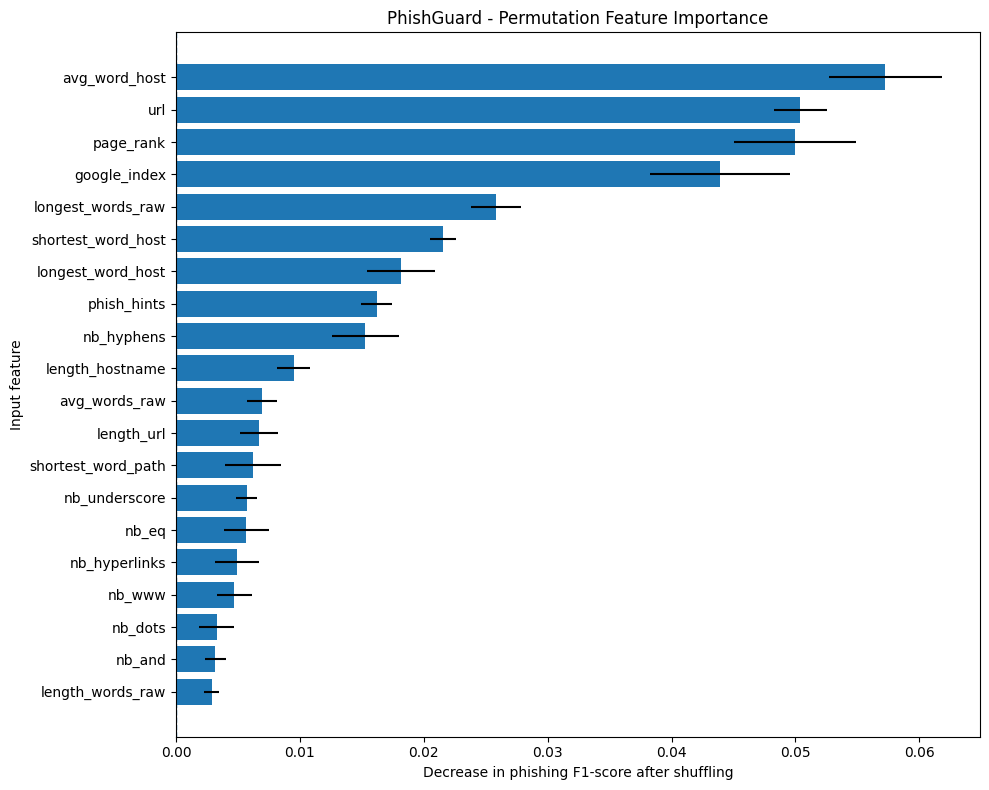

,Feature,Importance,Std
48,avg_word_host,0.057239,0.004564
0,url,0.050379,0.002130
81,page_rank,0.049970,0.004951
80,google_index,0.043888,0.005665
44,longest_words_raw,0.025837,0.002021
42,shortest_word_host,0.021539,0.001037
45,longest_word_host,0.018172,0.002736
50,phish_hints,0.016187,0.001234
5,nb_hyphens,0.015259,0.002702
2,length_hostname,0.009505,0.001325


In [23]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_model,
    X_val,
    y_val,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Importance", ascending=False)

top_features = importance_df.head(20).sort_values("Importance")

plt.figure(figsize=(10, 8))
plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"]
)
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Decrease in phishing F1-score after shuffling")
plt.ylabel("Input feature")
plt.title("PhishGuard - Permutation Feature Importance")
plt.tight_layout()

# Save image immediately
plt.savefig(os.path.join(OUTPUT_DIR, "permutation_feature_importance.png"), dpi=300)
plt.show()

display(importance_df.head(20))

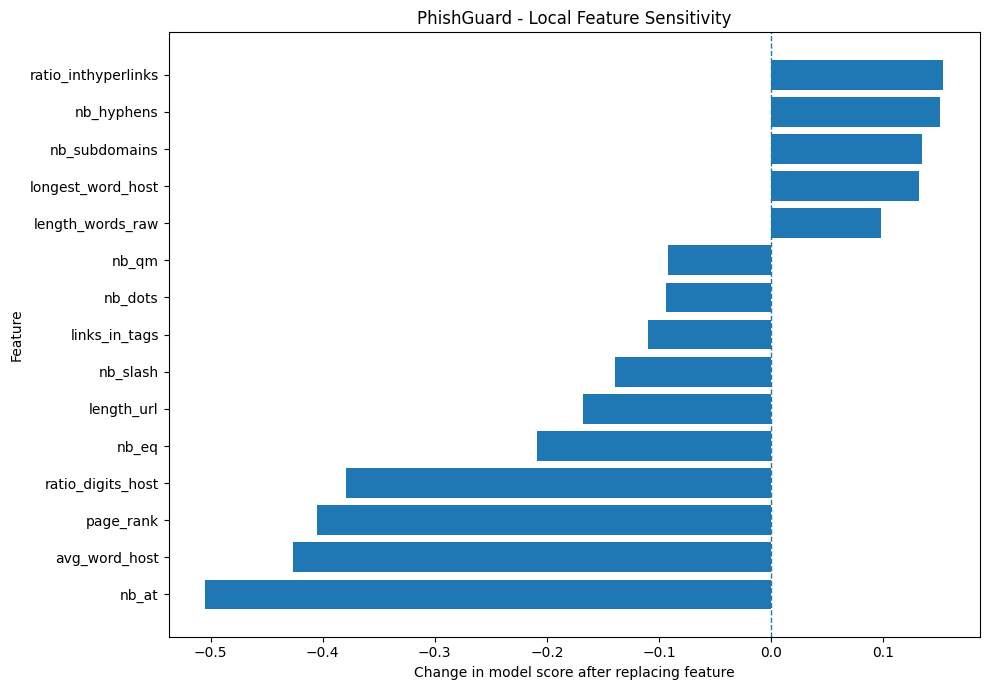

Original model score: 2.7119


In [24]:
# Pick one URL from the validation set.
sample = X_val.iloc[[0]].copy()
base_prediction = best_model.predict(sample)[0]

def get_score(row):
    if hasattr(best_model, "decision_function"):
        return float(best_model.decision_function(row)[0])
    if hasattr(best_model, "predict_proba"):
        return float(best_model.predict_proba(row)[0, 1])
    return float(best_model.predict(row)[0])

base_score = get_score(sample)
changes = []

for feature in X_val.columns:
    if feature == "url":
        continue
    modified = sample.copy()
    if feature in X_train.columns:
        median_value = pd.to_numeric(
            X_train[feature], errors="coerce"
        ).median()
        if pd.notna(median_value):
            modified[feature] = median_value
        else:
            continue
    else:
        continue
    modified_score = get_score(modified)
    changes.append({
        "Feature": feature,
        "Original value": sample[feature].iloc[0],
        "Score change after replacement": modified_score - base_score
    })

local_df = pd.DataFrame(changes)
local_df["Absolute change"] = local_df["Score change after replacement"].abs()
local_df = local_df.nlargest(15, "Absolute change").sort_values(
    "Score change after replacement"
)

plt.figure(figsize=(10, 7))
plt.barh(
    local_df["Feature"],
    local_df["Score change after replacement"]
)
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Change in model score after replacing feature")
plt.ylabel("Feature")
plt.title("PhishGuard - Local Feature Sensitivity")
plt.tight_layout()

# Save image immediately
plt.savefig(os.path.join(OUTPUT_DIR, "local_feature_sensitivity.png"), dpi=300)
plt.show()

print("Original model score:", round(base_score, 4))

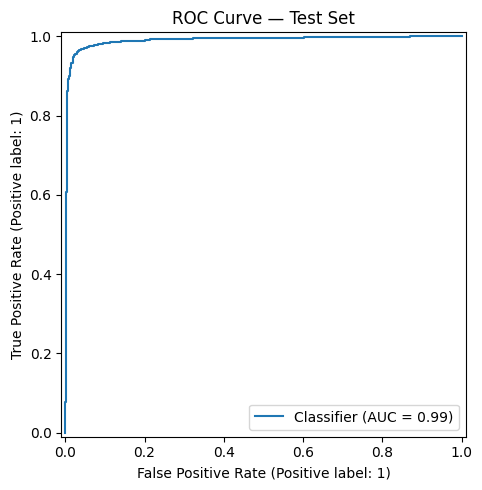

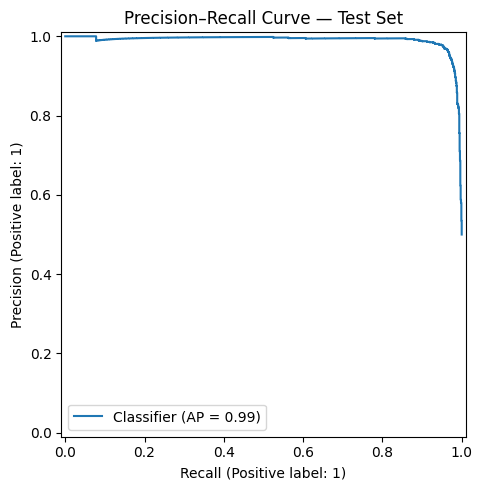

In [25]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_test,
    test_scores,
    ax=ax
)
ax.set_title("ROC Curve — Test Set")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "roc_curve_test.png"), dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(
    y_test,
    test_scores,
    ax=ax
)
ax.set_title("Precision–Recall Curve — Test Set")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "precision_recall_curve_test.png"), dpi=300)
plt.show()

**Save model**

In [15]:
OUTPUT_DIR = "/content/phishguard_artifacts"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

model_path = os.path.join(
    OUTPUT_DIR,
    "phishguard_model.joblib"
)

joblib.dump(
    best_model,
    model_path
)

metadata = {
    "project": "PhishGuard",
    "selected_model": best_name,
    "url_column": "url",
    "target_column": "status",
    "target_mapping": {
        "legitimate": 0,
        "phishing": 1
    },
    "numeric_features": numeric_features,
    "removed_features": drop_cols,
    "random_seed": SEED
}

with open(
    os.path.join(OUTPUT_DIR, "metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=2)

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "validation_model_comparison.csv"
    ),
    index=False
)

pd.DataFrame([test_metrics]).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "final_test_metrics.csv"
    ),
    index=False
)

print("Artifacts saved:")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(os.path.join(OUTPUT_DIR, filename))

Artifacts saved:
/content/phishguard_artifacts/final_test_metrics.csv
/content/phishguard_artifacts/metadata.json
/content/phishguard_artifacts/phishguard_model.joblib
/content/phishguard_artifacts/validation_model_comparison.csv
